In [ ]:
import pandas as pd
import numpy as np
from pandas.plotting import andrews_curves
import matplotlib.pyplot as plt
df = pd.read_csv('./dataassets/players_data-2025_2026.csv')



print(df.columns.tolist())
print("=======")
print(df.shape)
features = ['Min', 'Gls', 'Ast', 'Sh', 'SoT', "Fld"]
df_fw = df[df['Pos'].str.contains("FW", na=False)].reset_index(drop=True)
star_player = df_fw['Player'] == "Kylian Mbappé"
print(df_fw[star_player])


['Rk', 'Player', 'Nation', 'Pos', 'Squad', 'Comp', 'Age', 'Born', 'MP', 'Starts', 'Min', '90s', 'Gls', 'Ast', 'G+A', 'G-PK', 'PK', 'PKatt', 'CrdY', 'CrdR', 'G+A-PK', 'Rk_stats_keeper', 'Nation_stats_keeper', 'Pos_stats_keeper', 'Comp_stats_keeper', 'Age_stats_keeper', 'Born_stats_keeper', 'MP_stats_keeper', 'Starts_stats_keeper', 'Min_stats_keeper', '90s_stats_keeper', 'GA', 'GA90', 'SoTA', 'Saves', 'Save%', 'W', 'D', 'L', 'CS', 'CS%', 'PKatt_stats_keeper', 'PKA', 'PKsv', 'PKm', 'Rk_stats_shooting', 'Nation_stats_shooting', 'Pos_stats_shooting', 'Comp_stats_shooting', 'Age_stats_shooting', 'Born_stats_shooting', '90s_stats_shooting', 'Gls_stats_shooting', 'Sh', 'SoT', 'SoT%', 'Sh/90', 'SoT/90', 'G/Sh', 'G/SoT', 'PK_stats_shooting', 'PKatt_stats_shooting', 'Rk_stats_playing_time', 'Nation_stats_playing_time', 'Pos_stats_playing_time', 'Comp_stats_playing_time', 'Age_stats_playing_time', 'Born_stats_playing_time', 'MP_stats_playing_time', 'Min_stats_playing_time', 'Mn/MP', 'Min%', '90s_s

In [21]:
X = df_fw[features]
print(X)
X_scaled = (X - X.mean())/ X.std()
X_scaled.index = df_fw['Player']
print(X_scaled.head())

      Min  Gls  Ast  Sh  SoT  Fld
0    2449    4    5  47   17   51
1     681    2    0  17    4    3
2    2584    6    4  84   22   42
3     286    2    0   9    3    0
4     698    2    0  23    9   11
..    ...  ...  ...  ..  ...  ...
757  1131    1    1  26   12   17
758   626    2    1  25    9    6
759  1142    6    0  28   14   13
760   386    0    1  10    5    8
761    74    0    0   5    0    1

[762 rows x 6 columns]
                          Min       Gls       Ast        Sh       SoT  \
Player                                                                  
Brenden Aaronson     1.725200  0.129762  1.817692  0.819116  0.654380   
Jones El-Abdellaoui -0.398414 -0.333370 -0.759683 -0.378593 -0.588628   
Matthis Abline       1.887354  0.592894  1.302217  2.296290  1.132459   
Tammy Abraham       -0.872864 -0.333370 -0.759683 -0.697982 -0.684244   
Giorgi Abuashvili   -0.377995 -0.333370 -0.759683 -0.139052 -0.110548   

                          Fld  
Player                  

In [22]:
star_vector = X_scaled.loc['Kylian Mbappé'].values
candidates = X_scaled.drop('Kylian Mbappé').values
candidates_name = X_scaled.drop('Kylian Mbappé').index.values
print(star_vector)
print(candidates.shape)

[1.90537073 4.99264771 1.81769247 4.77155545 5.05271414 1.18320269]
(761, 6)


In [ ]:
eucli_distance = np.sqrt(((candidates - star_vector)**2).sum(axis=1))
idx = eucli_distance.argmin()
print("Reemplazo encontrado (Distancia Euclidiana): ", candidates_name[idx])
print("Distancia: ", eucli_distance[idx])

Reemplazo encontrado =  Erling Haaland
Distancia:  2.0017081010898363


In [25]:
def manhattan(a,b):
    return np.abs(a-b).sum(axis=1)
dist_manh = manhattan(candidates, star_vector)
idx_m = dist_manh.argmin()
print("Reemplazo (Manhattan): ", candidates_name[idx_m])
print("Distancia: ", dist_manh[idx_m])



Reemplazo (Manhattan):  Erling Haaland
Distancia:  4.276210292684434


In [26]:
print("Euclidiana:", candidates_name[idx], "| Manhattan:", candidates_name[idx_m])

Euclidiana: Erling Haaland | Manhattan: Erling Haaland


#### Diferencia Matematica
La Euclidiana eleva al cuadrado las diferencias, así que castiga mucho más una diferencia grande en una sola característica. Una diferencia de 3 pesa 9; una de 1 pesa 1.
La Manhattan suma las diferencias tal cual, de modo que todas pesan proporcionalmente. Es más tolerante a un solo valor muy distinto.

#### Diferencia Geométrica
La Euclidiana es la línea recta entre dos puntos.
La Manhattan solo se mueve paralela a los ejes, como el taxi. Por eso siempre es mayor o igual que la Euclidiana.

Aunque el primer lugar coincida, el top 5 puede cambiar de orden

In [28]:
top5_e = eucli_distance.argsort()[:5]
top5_m = dist_manh.argsort()[:5]

print("Top 5 Euclidiana:", candidates_name[top5_e])
print("Top 5 Manhattan:", candidates_name[top5_m])

Top 5 Euclidiana: ['Erling Haaland' 'Deniz Undav' 'Harry Kane' 'Vedat Muriqi'
 'Lautaro Martínez']
Top 5 Manhattan: ['Erling Haaland' 'Harry Kane' 'Deniz Undav' 'Vedat Muriqi'
 'Esteban Lepaul']


## Análisis Crítico: Euclidiana vs. Manhattan

**¿Sugirieron al mismo jugador?** Sí. Ambas métricas eligieron a **Erling Haaland**
(Manchester City) como el reemplazo más similar a Kylian Mbappé.

| | Mbappé | Haaland |
|---|---|---|
| Minutos | 2599 | 2953 |
| Goles | 25 | 27 |
| Asistencias | 5 | 8 |
| Tiros | 146 | 126 |
| Tiros a puerta | 63 | 59 |
| Faltas recibidas | 36 | 25 |

Haaland se parece a Mbappé de forma pareja en todas las características, sin una
diferencia extrema en alguna. Por eso ambas métricas coinciden en el primer lugar.

**Diferencias observables:**

1. **El ranking cambia después del primer lugar.** Con Euclidiana, el 2.º lugar es
   Deniz Undav y el 3.º Harry Kane; con Manhattan se invierten. Además, Lautaro
   Martínez aparece en el top 5 Euclidiano pero no en el de Manhattan.

2. **Forma de penalizar.** La Euclidiana eleva al cuadrado cada diferencia, por lo que
   castiga mucho una diferencia grande en una sola característica. La Manhattan suma
   las diferencias absolutas, así que reparte la penalización de forma proporcional.
   Kane sube en Manhattan porque sus diferencias son pequeñas pero repartidas; Undav
   baja porque tiene diferencias más concentradas.

3. **Magnitud.** Las distancias Manhattan siempre son mayores o iguales que las
   Euclidianas (4.28 vs. 2.00 para Haaland), porque recorren el espacio por los ejes
   en lugar de en línea recta.

4. **Observación.** Mbappé es un caso atípico (Z ≈ 5 en goles y tiros a puerta), así
   que incluso su "clon" está a una distancia considerable: el algoritmo encuentra al
   jugador *menos lejano*, no a uno idéntico.

Jugador aleatorio: Vakoun Bayo


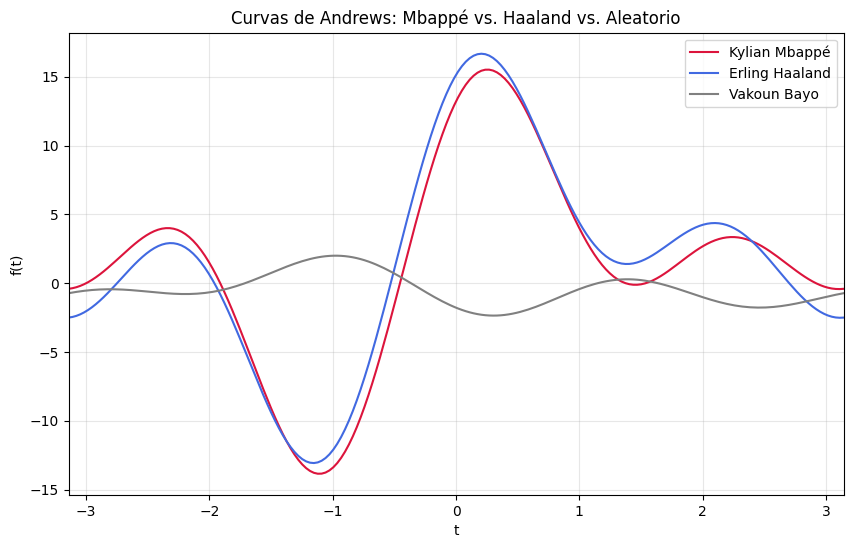

In [ ]:


# Tercer jugador aleatorio (semilla fija para que sea reproducible)
rng = np.random.default_rng(42)
otros = [n for n in candidates_name if n != 'Erling Haaland']
aleatorio = rng.choice(otros)
print("Jugador aleatorio:", aleatorio)

# Seleccionar los 3 vectores escalados
seleccion = X_scaled.loc[['Kylian Mbappé', 'Erling Haaland', aleatorio]].reset_index()

# Graficar
plt.figure(figsize=(10, 6))
andrews_curves(seleccion, 'Player', color=['crimson', 'royalblue', 'gray'])
plt.title('Curvas de Andrews: Mbappé vs. Haaland vs. Aleatorio')
plt.xlabel('t')
plt.ylabel('f(t)')
plt.grid(alpha=0.3)
plt.show()